# Why do some catchments have negative NSE or KGE?

This is an **exploratory post-hoc analysis**, not a new LSTM training experiment.
Keep this notebook beside **`basin_diagnostic_dataset.csv`** and run all cells in order.
These are the only two project files needed. Python dependencies: numpy, pandas, scipy,
matplotlib and a Jupyter/IPython kernel. Output tables, figures and a findings report are regenerated.

Five experiments are included. The four 1980–1999 training experiments are compared on 2005–2009.
The extended ERA5 experiment trains on 1950–2009 and tests on 2015–2023-01-03; analyze it separately.
All 1,426 basin IDs are retained for each setup, including missing/undefined metrics.

## Questions
1. Which specific basins fail, and do the same basins fail across models?
2. Are failures associated with low/zero flow, limited variability, flashiness, snow, aridity or changes between training and testing?
3. Are terrain, soils, land cover, storage and permeability different in poorly performing basins?
4. Is the error mostly timing/correlation, amplitude, or volume bias?

**Interpretation:** NSE < 0 is worse than the observed test-period mean-flow NSE reference.
KGE < 0 is a useful requested flag, but is not the corresponding mean-flow benchmark.
We separately report KGE < 1−√2 (approximately −0.414).
See [Knoben et al. (2019)](https://hess.copernicus.org/articles/23/4323/2019/).
Neither threshold establishes a physical cause. Multiple seeds, independent years, geographic dependence and observations require further checks.


## 1. Read the one input CSV and audit its contents

One row represents one **basin × experiment**: 7,130 rows. Basin attributes repeat across experiments;
never pool these repeated rows as independent catchments in significance tests.
The CSV was assembled once from saved model comparisons, daily prepared arrays, daily predictions,
the transposed CAMELS-SPAT lumped attributes, and PCA10 summaries. The notebook analyzes those summaries;
it does not need the original daily archives or preparation script.


In [1]:
from pathlib import Path
import csv, json, hashlib, math, warnings
import numpy as np
import pandas as pd
import scipy
from scipy.stats import mannwhitneyu, fisher_exact, spearmanr
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CSV_PATH=Path.cwd()/'basin_diagnostic_dataset.csv'
OUT=CSV_PATH.parent/'analysis_outputs'
OUT.mkdir(exist_ok=True)
SEED=42
PRIMARY='Daymet_PCA10'
MIN_GROUP=10
KGE_MEAN_REFERENCE=1-np.sqrt(2)
df=pd.read_csv(CSV_PATH,dtype={'basin_id':str})
assert len(df)==7130 and df.basin_id.nunique()==1426
assert not df.duplicated(['basin_id','experiment']).any()
assert df.groupby('experiment').size().eq(1426).all()
assert df.groupby('experiment').seen_unseen.value_counts().groupby(level=0).apply(lambda x: sorted(x.tolist())).apply(lambda x:x==[100,1326]).all()
assert df.groupby('basin_id').seen_unseen.nunique().eq(1).all()
assert df.groupby('basin_id').climate_class.nunique().le(1).all()
assert df.NSE.dropna().le(1.00001).all() and df.KGE.dropna().le(1.00001).all()
assert df.loc[df.n_scored_days.fillna(0)>0,'prediction_file_present'].eq(1).all(), 'Missing predictions for scored basins'
numeric=df.select_dtypes(include='number').columns
df[numeric]=df[numeric].replace([np.inf,-np.inf],np.nan)
quality=[]
for col,lo,hi in [('attr_open_water_fraction',0,1),('attr_reservoir_fraction',0,1),('attr_forest_fraction',0,1),('attr_porosity_mean',0,1),('attr_slope_mean',0,90)]:
    bad=df[col].notna()&~df[col].between(lo,hi)
    for _,r in df.loc[bad,['basin_id','experiment',col]].iterrows():quality.append(dict(basin_id=r.basin_id,experiment=r.experiment,field=col,raw_value=r[col],action='masked invalid physical range; basin retained'))
    df.loc[bad,col]=np.nan
pd.DataFrame(quality,columns=['basin_id','experiment','field','raw_value','action']).to_csv(OUT/'physical_range_quality_flags.csv',index=False)
metadata={
 'input_csv':CSV_PATH.name,'input_sha256':hashlib.sha256(CSV_PATH.read_bytes()).hexdigest(),
 'rows':len(df),'basins':df.basin_id.nunique(),'seed':SEED,
 'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,
 'method':'post-hoc basin-level analysis; strata analyzed separately; no causal attribution'}
(OUT/'analysis_provenance.json').write_text(json.dumps(metadata,indent=2))
display(df[['experiment','train_start','train_end_exclusive','test_start','test_end_exclusive']].drop_duplicates())
print('Input audit passed:',len(df),'rows;',df.basin_id.nunique(),'basins; only',CSV_PATH.name,'read.')


,experiment,train_start,train_end_exclusive,test_start,test_end_exclusive
0,Daymet_MetOnly,1980-01-01,2000-01-01,2005-01-01,2010-01-01
1,Daymet_MetAttr,1980-01-01,2000-01-01,2005-01-01,2010-01-01
2,Daymet_PCA10,1980-01-01,2000-01-01,2005-01-01,2010-01-01
3,ERA5_MetAttr,1980-01-01,2000-01-01,2005-01-01,2010-01-01
4,ERA5_Extended,1950-01-01,2010-01-01,2015-01-01,2023-01-04


Input audit passed: 7130 rows; 1426 basins; only basin_diagnostic_dataset.csv read.


## 2. Definitions, coverage and hydrological indicators

- Discharge: **mm/day**; m³/s = mm/day × basin area (km²) / 86.4. Negative/missing observations are excluded, never replaced with zero.
- Flow mean, median, maximum, population SD, CV, quantiles and zero fractions use all valid observations in the stated calendar period.
- Exact zero = Q = 0; near-zero = Q ≤ **0.01 mm/day**. These are observational flags, not proof of natural intermittency.
- Flashiness = sum of consecutive-day |ΔQ| / sum of consecutive-pair mean Q; observation gaps are not joined.
- Runoff ratio = ΣQ / ΣP on days where both are valid. Ratios above one are retained as possible storage, forcing or area/observation flags.
- Snow proxy = precipitation fraction on days with mean temperature < 0°C. It is not measured snowfall.
- Aridity proxy = ΣPET / ΣP on common valid days; PET methods differ between Daymet and ERA5.
- Low-flow, low-variability and high-flashiness flags use the lower/lower/upper quartile **of Seen basins within the same experiment**.
  These are relative study categories, not universal hydrological classes. Thresholds use observations, not model performance.
- Stored `climate_class` is the original pre-2000 Daymet precipitation-temperature proxy, not a formal climate classification.
- Surface clay/sand/silt fields retain original g/kg units. Land-cover, porosity and area fractions are unitless;
  elevation is m, slope degrees, basin area km², log-permeability follows the archive's logged m² convention.
- No direct karst, carbonate, abstraction, regulation-operation or gauge-rating diagnosis is available.
  Reservoir area and permeability are **proxies**, not proof of regulation or karst processes.

KGE correlation r, variability ratio α and bias ratio β use model/observation pairs used for scoring.
Test statistics and KGE components are explanatory diagnostics; their mathematical relation to the scores is not independent evidence of causation.


In [2]:
def flag(condition, valid):
    return pd.Series(np.where(valid,condition.astype(float),np.nan),index=df.index)
for metric in ('NSE','KGE'):
    df[metric+'_negative']=np.where(df[metric].notna(),(df[metric]<0).astype(float),np.nan)
    df[metric+'_below_minus_one']=np.where(df[metric].notna(),(df[metric]<-1).astype(float),np.nan)
df['KGE_below_mean_reference']=np.where(df.KGE.notna(),(df.KGE<KGE_MEAN_REFERENCE).astype(float),np.nan)
both=df.NSE.notna()&df.KGE.notna()
any_negative=(df.NSE<0)|(df.KGE<0)
df['either_negative']=np.where(any_negative,1.,np.where(both,0.,np.nan))
df['both_negative']=np.where(both,((df.NSE<0)&(df.KGE<0)).astype(float),np.nan)
df['scored_coverage']=df.n_scored_days/df.test_calendar_days
df['adequate_coverage']=(df.scored_coverage>=.8)&(df.n_scored_days>=365)
thresholds=[]
for experiment,g in df.groupby('experiment'):
    seen=g[g.seen_unseen=='Seen']
    for feature,quantile,label,direction in [
        ('test_q_mean_mm_day',.25,'low_flow_relative','low'),
        ('test_q_std_mm_day',.25,'low_variability_relative','low'),
        ('test_flashiness',.75,'high_flashiness_relative','high'),
        ('train_q_mean_mm_day',.25,'low_training_flow_relative','low')]:
        v=seen[feature].dropna(); cutoff=v.quantile(quantile)
        mask=df.experiment==experiment; valid=mask&df[feature].notna()
        cond=df[feature]<=cutoff if direction=='low' else df[feature]>=cutoff
        if label not in df:df[label]=np.nan
        df.loc[valid,label]=cond[valid].astype(float)
        thresholds.append(dict(experiment=experiment,feature=feature,category=label,seen_reference_n=len(v),cutoff=cutoff))
definitions=[('zero_flow_1pct','test_zero_flow_fraction',lambda x:x>=.01),
 ('near_zero_5pct','test_near_zero_fraction',lambda x:x>=.05),
 ('arid_pet_gt_p','test_aridity_pet_over_prcp',lambda x:x>1),
 ('snow_proxy_ge_40pct','test_snow_precip_fraction_proxy',lambda x:x>=.4),
 ('runoff_ratio_gt_one','test_runoff_ratio',lambda x:x>1),
 ('test_flow_less_than_half_train','test_train_q_mean_ratio',lambda x:x<.5),
 ('open_water_ge_5pct','attr_open_water_fraction',lambda x:x>=.05),
 ('reservoir_ge_1pct','attr_reservoir_fraction',lambda x:x>=.01)]
for label,col,fun in definitions:
    df[label]=np.where(df[col].notna(),fun(df[col]).astype(float),np.nan)
pd.DataFrame(thresholds).to_csv(OUT/'classification_thresholds.csv',index=False)
pd.DataFrame({'column':df.columns,'nonmissing':df.notna().sum().values,'dtype':df.dtypes.astype(str).values}).to_csv(OUT/'data_dictionary_and_coverage.csv',index=False)


/tmp/ipykernel_3193509/1169736644.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[metric+'_negative']=np.where(df[metric].notna(),(df[metric]<0).astype(float),np.nan)
/tmp/ipykernel_3193509/1169736644.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[metric+'_below_minus_one']=np.where(df[metric].notna(),(df[metric]<-1).astype(float),np.nan)
/tmp/ipykernel_3193509/1169736644.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perfo

## 3. How many basins fail? Identify the specific basins

Undefined scores remain separate from negative scores. A nonnegative KGE or NSE alone is not a general guarantee of an adequate hydrological model.
The catalogue contains every basin with either negative metric, including separate flags for severe scores and missing evidence.


In [3]:
def wilson(k,n):
    if not n:return (np.nan,np.nan)
    z=1.96;p=k/n;den=1+z*z/n
    center=(p+z*z/(2*n))/den; half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half,center+half
overview=[]
outcomes=['NSE_negative','KGE_negative','KGE_below_mean_reference','either_negative','both_negative','NSE_below_minus_one','KGE_below_minus_one']
for (model,split),g in df.groupby(['experiment','seen_unseen']):
    r=dict(experiment=model,seen_unseen=split,total=len(g),NSE_scored=g.NSE.notna().sum(),KGE_scored=g.KGE.notna().sum())
    for metric in ('NSE','KGE'):
        r[metric+'_mean']=g[metric].mean();r[metric+'_median']=g[metric].median()
    for outcome in outcomes:
        v=g[outcome].dropna(); k=int(v.sum());r[outcome+'_n']=k;r[outcome+'_rate']=k/len(v) if len(v) else np.nan
    overview.append(r)
overview=pd.DataFrame(overview)
overview.to_csv(OUT/'failure_summary_by_experiment_seen_unseen.csv',index=False)
catalog_cols=['basin_id','experiment','seen_unseen','country','basin_group','climate_class','NSE','KGE','n_scored_days','scored_coverage',
 'test_q_mean_mm_day','test_q_max_mm_day','test_q_std_mm_day','test_q_cv','test_zero_flow_fraction','test_near_zero_fraction',
 'test_flashiness','test_runoff_ratio','test_aridity_pet_over_prcp','test_snow_precip_fraction_proxy',
 'KGE_r','KGE_alpha','KGE_beta','diagnostic_RMSE','diagnostic_MAE','pred_negative_fraction',
 'low_flow_squared_error_fraction','high_flow_squared_error_fraction','metric_status']
catalog=df.loc[df.either_negative==1,catalog_cols].sort_values(['experiment','NSE'])
catalog.to_csv(OUT/'negative_basin_catalog.csv',index=False)
df[catalog_cols+outcomes].to_csv(OUT/'all_basin_diagnostics.csv',index=False)
display(overview[['experiment','seen_unseen','NSE_scored','NSE_negative_n','KGE_negative_n','KGE_below_mean_reference_n','either_negative_n']])
display(Markdown('### Worst PCA10 basin scores (all scored basins retained in exports)'))
display(catalog[catalog.experiment==PRIMARY].head(15))


,experiment,seen_unseen,NSE_scored,NSE_negative_n,KGE_negative_n,KGE_below_mean_reference_n,either_negative_n
0,Daymet_MetAttr,Seen,1317,104,122,69,150
1,Daymet_MetAttr,Unseen,100,9,7,4,12
2,Daymet_MetOnly,Seen,1317,140,200,112,228
3,Daymet_MetOnly,Unseen,100,7,10,6,13
4,Daymet_PCA10,Seen,1317,84,111,59,137
5,Daymet_PCA10,Unseen,100,8,14,5,17
6,ERA5_Extended,Seen,1310,83,113,50,139
7,ERA5_Extended,Unseen,99,5,7,1,10
8,ERA5_MetAttr,Seen,1317,86,116,42,148
9,ERA5_MetAttr,Unseen,100,6,6,3,9


### Worst PCA10 basin scores (all scored basins retained in exports)

,basin_id,experiment,seen_unseen,country,basin_group,climate_class,NSE,KGE,n_scored_days,scored_coverage,...,test_snow_precip_fraction_proxy,KGE_r,KGE_alpha,KGE_beta,diagnostic_RMSE,diagnostic_MAE,pred_negative_fraction,low_flow_squared_error_fraction,high_flow_squared_error_fraction,metric_status
1442,CAN_05CK005,Daymet_PCA10,Seen,CAN,meso-scale,mixed_proxy,-95.067834,-63.866482,1225.0,0.670865,...,0.127670,-0.040542,6.365335,65.635828,0.069174,0.060519,0.136327,0.711908,0.037548,scored
1617,CAN_05GA012,Daymet_PCA10,Seen,CAN,macro-scale,mixed_proxy,-73.833873,-52.513203,1225.0,0.670865,...,0.157037,0.461472,3.637994,54.445428,0.074706,0.069267,0.008163,0.634723,0.035096,scored
1607,CAN_05GA008,Daymet_PCA10,Seen,CAN,macro-scale,mixed_proxy,-17.536488,-19.915303,1225.0,0.670865,...,0.153828,0.442788,1.806006,21.892340,0.070183,0.065733,0.008980,0.555441,0.011438,scored
6282,USA_09306242,Daymet_PCA10,Seen,USA,meso-scale,mixed_proxy,-13.895050,-4.082595,1826.0,1.000000,...,0.251059,-0.037166,2.394373,5.776273,0.123026,0.096560,0.018072,0.175051,0.019086,scored
5617,USA_06477500,Daymet_PCA10,Seen,USA,macro-scale,mixed_proxy,-11.731370,-2.203453,1826.0,1.000000,...,0.109572,0.449267,3.893697,2.259097,0.600841,0.093150,0.489595,0.000418,0.745790,scored
1237,CAN_05AH050,Daymet_PCA10,Seen,CAN,macro-scale,mixed_proxy,-9.829173,-13.558406,1366.0,0.748083,...,0.229926,0.281149,1.836127,15.516588,0.091089,0.077784,0.008053,0.665095,0.012888,scored
5562,USA_06409000,Daymet_PCA10,Seen,USA,meso-scale,mixed_proxy,-7.990761,-0.805176,1826.0,1.000000,...,0.325966,0.617819,2.485684,1.951493,0.139293,0.104714,0.000000,0.074529,0.009901,scored
5557,USA_06408700,Daymet_PCA10,Seen,USA,headwater,mixed_proxy,-7.456338,-0.038088,1826.0,1.000000,...,0.378536,0.081448,1.266169,1.403785,0.216745,0.188481,0.000000,0.163772,0.001564,scored
5682,USA_06847900,Daymet_PCA10,Seen,USA,macro-scale,rain_proxy,-7.115427,-4.411414,1826.0,1.000000,...,0.097636,0.698820,3.372763,5.854141,0.135386,0.047789,0.264513,0.005866,0.333325,scored
5927,USA_07301410,Daymet_PCA10,Seen,USA,meso-scale,rain_proxy,-6.221213,-1.993181,1826.0,1.000000,...,0.040087,0.154812,2.261036,3.579647,0.184642,0.096848,0.002191,0.043978,0.138460,scored


## 4. Repeated failures across comparable experiments

This section compares only the four **2005–2009** experiments. A persistent failure is either-negative
in at least three of the four setups, with scores available in all four. This is a study definition,
not a universal category. Extended ERA5 is excluded because its testing years differ.


In [4]:
same=df[df.test_start=='2005-01-01']
persistent=same.groupby('basin_id').agg(seen_unseen=('seen_unseen','first'),basin_group=('basin_group','first'),
 climate_class=('climate_class','first'),models_scored=('either_negative','count'),models_negative=('either_negative','sum'),
 NSE_models_negative=('NSE_negative','sum'),KGE_models_negative=('KGE_negative','sum'))
persistent['persistent_3of4']=(persistent.models_scored==4)&(persistent.models_negative>=3)
persistent.to_csv(OUT/'persistent_failures_2005_2009.csv')
display(persistent.groupby('seen_unseen').agg(basins=('models_scored','size'),persistent_3of4=('persistent_3of4','sum')))


,basins,persistent_3of4
seen_unseen,,
Seen,1326,124
Unseen,100,10


## 5. Which characteristics differ from other basins?

For each model and Seen/Unseen stratum, compare negative versus nonnegative scores separately for NSE and KGE.
Report overall mean/median, group medians, IQR and **rank-biserial effect size**. A positive effect means the feature
is generally higher in negative-score basins. Two-sided Mann–Whitney tests are exploratory; Benjamini–Hochberg
adjustment is applied within each model × split × metric family. Require at least 10 valid basins in each group.
Results do not account fully for nested/shared watersheds or spatial correlation, and should not be presented as causal or confirmatory.


In [5]:
FEATURES=[
 'train_q_mean_mm_day','train_q_std_mm_day','train_q_cv','train_zero_flow_fraction',
 'test_q_mean_mm_day','test_q_median_mm_day','test_q_max_mm_day','test_q_std_mm_day','test_q_cv',
 'test_zero_flow_fraction','test_near_zero_fraction','test_flashiness','test_q_seasonal_amplitude',
 'test_top1pct_flow_volume_fraction','test_runoff_ratio','test_q_coverage','scored_coverage',
 'test_prcp_mean','test_prcp_cv','test_prcp_p95_mm_day','test_wet_day_fraction','test_longest_dry_spell_days',
 'test_pet_mean','test_aridity_pet_over_prcp','test_temperature_mean_degC','test_snow_precip_fraction_proxy',
 'test_train_q_mean_ratio','test_train_prcp_mean_ratio',
 'attr_basin_area','attr_elev_mean','attr_slope_mean','attr_stream_density','attr_elongation_ratio',
 'attr_open_water_fraction','attr_reservoir_fraction','attr_regolith_thickness_mean',
 'attr_porosity_mean','attr_log_permeability_mean','attr_forest_fraction','attr_lc2_grassland_fraction',
 'attr_lc2_cropland_fraction','attr_lc2_permanent_wetland_fraction',
 'attr_clay_0-5cm_mean_mean','attr_sand_0-5cm_mean_mean','pca_n_subbasins']
FEATURES=[f for f in FEATURES if f in df and df[f].notna().any()]
def bh(p):
    p=np.asarray(p,float);out=np.full(p.shape,np.nan);valid=np.flatnonzero(np.isfinite(p));order=valid[np.argsort(p[valid])]
    if len(order):out[order]=np.minimum(1,np.minimum.accumulate((p[order]*len(order)/np.arange(1,len(order)+1))[::-1])[::-1])
    return out
contrasts=[];correlations=[]
for (model,split),g in df.groupby(['experiment','seen_unseen']):
    for metric in ('NSE','KGE'):
        valid=g[g[metric].notna()]
        for feature in FEATURES:
            a=valid.loc[valid[metric]<0,feature].dropna();b=valid.loc[valid[metric]>=0,feature].dropna();allv=valid[feature].dropna()
            r=dict(experiment=model,seen_unseen=split,metric=metric,feature=feature,n_negative=len(a),n_nonnegative=len(b),
                   overall_mean=allv.mean(),overall_median=allv.median(),negative_mean=a.mean(),nonnegative_mean=b.mean(),
                   negative_median=a.median(),nonnegative_median=b.median(),negative_q1=a.quantile(.25),negative_q3=a.quantile(.75),
                   nonnegative_q1=b.quantile(.25),nonnegative_q3=b.quantile(.75),rank_biserial=np.nan,p_value=np.nan)
            if min(len(a),len(b))>=MIN_GROUP and allv.nunique()>1:
                u,p=mannwhitneyu(a,b,alternative='two-sided',method='asymptotic')
                r.update(rank_biserial=2*u/(len(a)*len(b))-1,p_value=p)
            contrasts.append(r)
            pair=valid[[feature,metric]].dropna()
            if len(pair)>=30 and pair[feature].nunique()>1:
                rho,p=spearmanr(pair[feature],pair[metric]);correlations.append(dict(experiment=model,seen_unseen=split,
                        metric=metric,feature=feature,n=len(pair),spearman_rho=rho,p_value=p))
contrasts=pd.DataFrame(contrasts)
contrasts['q_BH']=contrasts.groupby(['experiment','seen_unseen','metric']).p_value.transform(lambda x:bh(x))
contrasts.to_csv(OUT/'feature_group_contrasts.csv',index=False)
correlations=pd.DataFrame(correlations)
correlations['q_BH']=correlations.groupby(['experiment','seen_unseen','metric']).p_value.transform(lambda x:bh(x))
correlations.to_csv(OUT/'continuous_score_associations.csv',index=False)
for split in ('Seen','Unseen'):
    display(Markdown('### PCA10: '+split+' — strongest descriptive contrasts'))
    z=contrasts[(contrasts.experiment==PRIMARY)&(contrasts.seen_unseen==split)&(contrasts.metric=='NSE')].copy()
    z['abs_effect']=z.rank_biserial.abs()
    display(z.sort_values('abs_effect',ascending=False)[['feature','n_negative','n_nonnegative','overall_median','negative_median','nonnegative_median','rank_biserial','q_BH']].head(15))


### PCA10: Seen — strongest descriptive contrasts

,feature,n_negative,n_nonnegative,overall_median,negative_median,nonnegative_median,rank_biserial,q_BH
367,test_q_std_mm_day,84,1233,1.772786,0.154303,1.883999,-0.791025,2.733659e-32
366,test_q_max_mm_day,84,1233,19.913486,2.147995,21.602623,-0.783301,5.786545e-32
361,train_q_std_mm_day,84,1233,1.876068,0.257368,1.979405,-0.726007,1.110552e-27
364,test_q_mean_mm_day,84,1233,1.054226,0.067983,1.108877,-0.683409,1.046884e-24
383,test_aridity_pet_over_prcp,84,1233,0.801160,1.407559,0.778882,0.677596,2.145809e-24
360,train_q_mean_mm_day,84,1233,1.047846,0.082590,1.087179,-0.667594,8.862567e-24
374,test_runoff_ratio,84,1233,0.383386,0.041367,0.393830,-0.627351,3.756350e-21
377,test_prcp_mean,84,1233,2.829621,1.360409,2.901402,-0.612598,2.906258e-20
380,test_wet_day_fraction,84,1233,0.324206,0.226999,0.332968,-0.604256,8.660452e-20
365,test_q_median_mm_day,84,1233,0.465499,0.017826,0.487615,-0.573070,6.212104e-18


### PCA10: Unseen — strongest descriptive contrasts

,feature,n_negative,n_nonnegative,overall_median,negative_median,nonnegative_median,rank_biserial,q_BH
450,train_q_mean_mm_day,8,92,1.021343,0.197354,1.161593,NaN,NaN
451,train_q_std_mm_day,8,92,2.100986,0.447897,2.359279,NaN,NaN
452,train_q_cv,8,92,1.692711,1.882776,1.681462,NaN,NaN
453,train_zero_flow_fraction,8,92,0.000000,0.000000,0.000000,NaN,NaN
454,test_q_mean_mm_day,8,92,1.071522,0.232056,1.152388,NaN,NaN
455,test_q_median_mm_day,8,92,0.461764,0.116157,0.508924,NaN,NaN
456,test_q_max_mm_day,8,92,21.852197,3.044258,25.100232,NaN,NaN
457,test_q_std_mm_day,8,92,1.820628,0.299068,2.089669,NaN,NaN
458,test_q_cv,8,92,1.586430,1.461061,1.586430,NaN,NaN
459,test_zero_flow_fraction,8,92,0.000000,0.000000,0.000000,NaN,NaN


## 6. Do poorly performing basins cluster in particular classes?

Report the **failure rate within each class**, not just the composition of the failing group.
Otherwise a common basin type can appear overrepresented simply because it dominates the dataset.
Wilson intervals show uncertainty. For binary process indicators, Fisher tests and risk ratios compare flagged with unflagged basins;
zero event cells receive a 0.5 correction for the ratio only. Small groups are retained descriptively and labelled.


In [6]:
CATEGORIES=['low_flow_relative','low_variability_relative','high_flashiness_relative','low_training_flow_relative',
 'zero_flow_1pct','near_zero_5pct','arid_pet_gt_p','snow_proxy_ge_40pct','runoff_ratio_gt_one',
 'test_flow_less_than_half_train','open_water_ge_5pct','reservoir_ge_1pct']
rates=[];risks=[]
for (model,split),g in df.groupby(['experiment','seen_unseen']):
    for outcome in ['NSE_negative','KGE_negative','KGE_below_mean_reference','either_negative']:
        for feature in ['country','basin_group','climate_class']+CATEGORIES:
            for cls,h in g.groupby(feature,dropna=True):
                v=h[outcome].dropna();n=len(v);k=int(v.sum());lo,hi=wilson(k,n)
                rates.append(dict(experiment=model,seen_unseen=split,outcome=outcome,classification=feature,category=cls,
                                  n_scored=n,n_negative=k,negative_rate=k/n if n else np.nan,CI95_low=lo,CI95_high=hi,small_group=n<MIN_GROUP))
            if feature in CATEGORIES:
                h=g[[feature,outcome]].dropna();yes=h[h[feature]==1][outcome];no=h[h[feature]==0][outcome]
                a=int(yes.sum());b=len(yes)-a;c=int(no.sum());d=len(no)-c
                p=fisher_exact([[a,b],[c,d]])[1] if len(yes) and len(no) else np.nan
                cells=np.array([a,b,c,d],float);corrected=bool(np.any(cells==0));cells+=.5 if corrected else 0
                aa,bb,cc,dd=cells;rr=(aa/(aa+bb))/(cc/(cc+dd)) if len(yes) and len(no) else np.nan
                risks.append(dict(experiment=model,seen_unseen=split,outcome=outcome,classification=feature,
                                  flagged_n=len(yes),unflagged_n=len(no),flagged_failure_rate=yes.mean(),unflagged_failure_rate=no.mean(),
                                  risk_ratio=rr,p_value=p,zero_cell_correction=corrected,small_group=min(len(yes),len(no))<MIN_GROUP))
rates=pd.DataFrame(rates);risks=pd.DataFrame(risks)
risks['q_BH']=risks.groupby(['experiment','seen_unseen','outcome']).p_value.transform(lambda x:bh(x))
rates.to_csv(OUT/'failure_rates_by_class.csv',index=False);risks.to_csv(OUT/'binary_class_risk_comparisons.csv',index=False)
for split in ('Seen','Unseen'):
    display(Markdown('### PCA10: '+split+' — class-specific NSE-negative rates'))
    display(rates[(rates.experiment==PRIMARY)&(rates.seen_unseen==split)&(rates.outcome=='NSE_negative')&
                  (rates.classification.isin(CATEGORIES))&(rates.category.astype(str).isin(['1.0','1']))][
                  ['classification','n_scored','n_negative','negative_rate','CI95_low','CI95_high','small_group']])


### PCA10: Seen — class-specific NSE-negative rates

,classification,n_scored,n_negative,negative_rate,CI95_low,CI95_high,small_group
513,low_flow_relative,330,62,0.187879,0.149415,0.233526,False
515,low_variability_relative,330,72,0.218182,0.177002,0.265848,False
517,high_flashiness_relative,329,21,0.063830,0.042124,0.095604,False
519,low_training_flow_relative,330,62,0.187879,0.149415,0.233526,False
521,zero_flow_1pct,242,41,0.169421,0.127411,0.221763,False
523,near_zero_5pct,334,53,0.158683,0.123409,0.201719,False
525,arid_pet_gt_p,418,69,0.165072,0.132563,0.203681,False
527,snow_proxy_ge_40pct,200,8,0.040000,0.020405,0.076933,False
529,runoff_ratio_gt_one,58,6,0.103448,0.048281,0.207883,False
531,test_flow_less_than_half_train,34,18,0.529412,0.367364,0.685487,False


### PCA10: Unseen — class-specific NSE-negative rates

,classification,n_scored,n_negative,negative_rate,CI95_low,CI95_high,small_group
641,low_flow_relative,32,7,0.218750,1.102370e-01,0.387553,False
643,low_variability_relative,29,7,0.241379,1.221827e-01,0.421080,False
645,high_flashiness_relative,22,0,0.000000,1.387779e-17,0.148660,False
647,low_training_flow_relative,30,6,0.200000,9.504978e-02,0.373060,False
649,zero_flow_1pct,17,3,0.176471,6.191014e-02,0.410299,False
651,near_zero_5pct,26,4,0.153846,6.149934e-02,0.335316,False
653,arid_pet_gt_p,37,7,0.189189,9.479859e-02,0.342050,False
655,snow_proxy_ge_40pct,16,0,0.000000,0.000000e+00,0.193613,False
657,runoff_ratio_gt_one,7,0,0.000000,0.000000e+00,0.354339,True
659,test_flow_less_than_half_train,4,2,0.500000,1.500357e-01,0.849964,True


## 7. Error components and observation-coverage sensitivity

For the original KGE, **r** measures correlation, **α** is simulated SD / observed SD, and **β** is simulated mean / observed mean.
The component farthest from its ideal value (r=α=β=1) is recorded as the dominant KGE component.
NSE is particularly sensitive to large errors relative to observed variance: RMSE / SD(observed) = √(1−NSE).
That identity diagnoses metric sensitivity; it does not establish why the simulation failed.

Repeat counts and the main class comparisons using ≥80% scored-day coverage and ≥365 paired days.
Changes in results indicate sensitivity to incomplete records. The notebook does not remove low-flow or zero-flow basins automatically.


In [7]:
parts=np.column_stack([(df.KGE_r-1).abs(),(df.KGE_alpha-1).abs(),(df.KGE_beta-1).abs()])
valid=np.isfinite(parts).all(axis=1)
df['dominant_KGE_component']='undefined'
df.loc[valid,'dominant_KGE_component']=np.array(['correlation/timing','variability/amplitude','mean-volume bias'])[np.argmax(parts[valid],axis=1)]
component_table=df[df.KGE_negative==1].groupby(['experiment','seen_unseen','dominant_KGE_component']).size().rename('basins').reset_index()
component_table.to_csv(OUT/'negative_KGE_error_components.csv',index=False)
coverage=[]
for (model,split),g in df.groupby(['experiment','seen_unseen']):
    for scope,h in [('all_scored',g),('coverage_ge80pct_and_days_ge365',g[g.adequate_coverage])]:
        for outcome in ('NSE_negative','KGE_negative','either_negative'):
            v=h[outcome].dropna();coverage.append(dict(experiment=model,seen_unseen=split,scope=scope,outcome=outcome,
                              n_scored=len(v),n_negative=int(v.sum()),rate=v.mean()))
pd.DataFrame(coverage).to_csv(OUT/'coverage_sensitivity.csv',index=False)
sensitivity=[]
for (model,split),g in df[df.adequate_coverage].groupby(['experiment','seen_unseen']):
    for feature in CATEGORIES:
        h=g[[feature,'NSE_negative']].dropna()
        for cls,v in h.groupby(feature):sensitivity.append(dict(experiment=model,seen_unseen=split,classification=feature,category=cls,
                      n=len(v),failure_rate=v.NSE_negative.mean()))
pd.DataFrame(sensitivity).to_csv(OUT/'class_rates_adequate_coverage.csv',index=False)
display(component_table[component_table.experiment==PRIMARY])
display(pd.DataFrame(coverage).query("experiment == @PRIMARY"))


/tmp/ipykernel_3193509/765373036.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['dominant_KGE_component']='undefined'


,experiment,seen_unseen,dominant_KGE_component,basins
9,Daymet_PCA10,Seen,correlation/timing,3
10,Daymet_PCA10,Seen,mean-volume bias,76
11,Daymet_PCA10,Seen,variability/amplitude,32
12,Daymet_PCA10,Unseen,mean-volume bias,12
13,Daymet_PCA10,Unseen,variability/amplitude,2


,experiment,seen_unseen,scope,outcome,n_scored,n_negative,rate
24,Daymet_PCA10,Seen,all_scored,NSE_negative,1317,84,0.063781
25,Daymet_PCA10,Seen,all_scored,KGE_negative,1317,111,0.084282
26,Daymet_PCA10,Seen,all_scored,either_negative,1317,137,0.104024
27,Daymet_PCA10,Seen,coverage_ge80pct_and_days_ge365,NSE_negative,1084,48,0.044280
28,Daymet_PCA10,Seen,coverage_ge80pct_and_days_ge365,KGE_negative,1084,59,0.054428
29,Daymet_PCA10,Seen,coverage_ge80pct_and_days_ge365,either_negative,1084,79,0.072878
30,Daymet_PCA10,Unseen,all_scored,NSE_negative,100,8,0.080000
31,Daymet_PCA10,Unseen,all_scored,KGE_negative,100,14,0.140000
32,Daymet_PCA10,Unseen,all_scored,either_negative,100,17,0.170000
33,Daymet_PCA10,Unseen,coverage_ge80pct_and_days_ge365,NSE_negative,85,4,0.047059


## 8. Figures and an automatically regenerated findings report

Tables contain exact basin IDs, descriptive differences, uncertainty and missing-data counts.
Figures focus on PCA10; all experiments remain available in the exported tables.
Means and medians use original values; plot limits do not alter the underlying analysis.


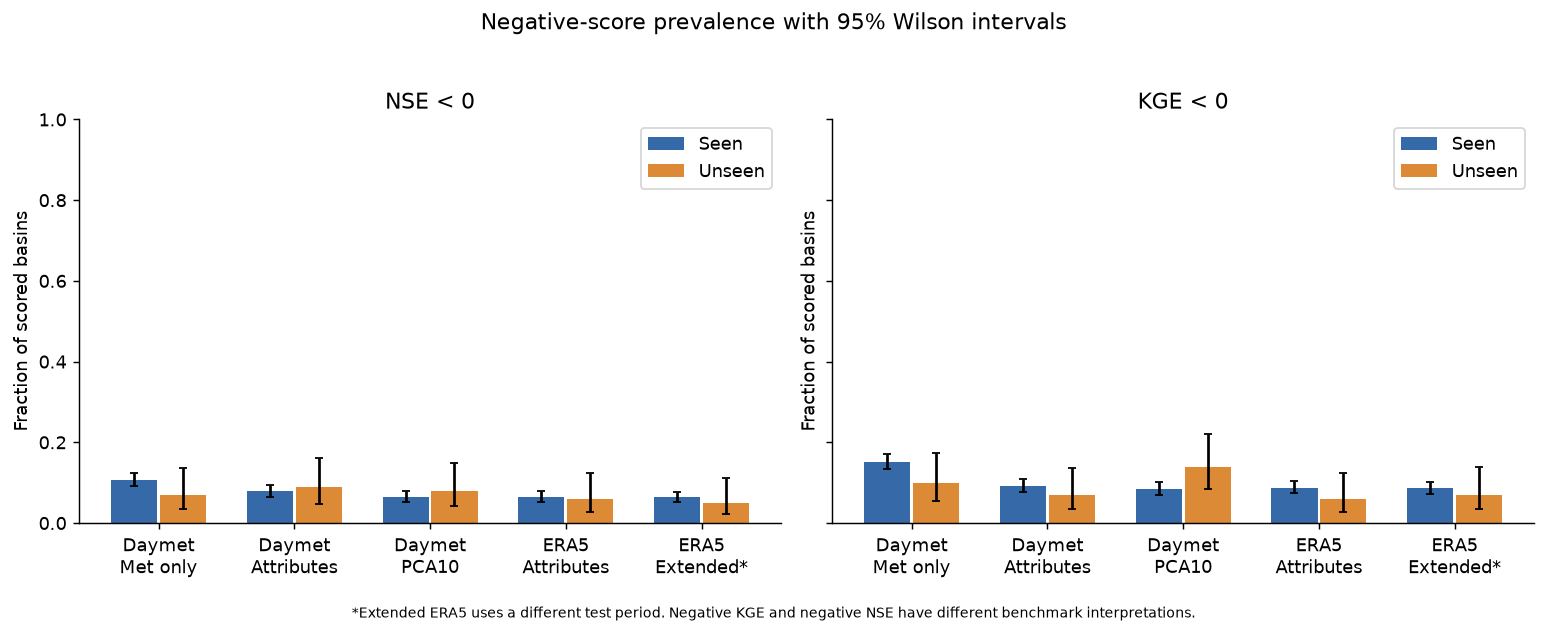

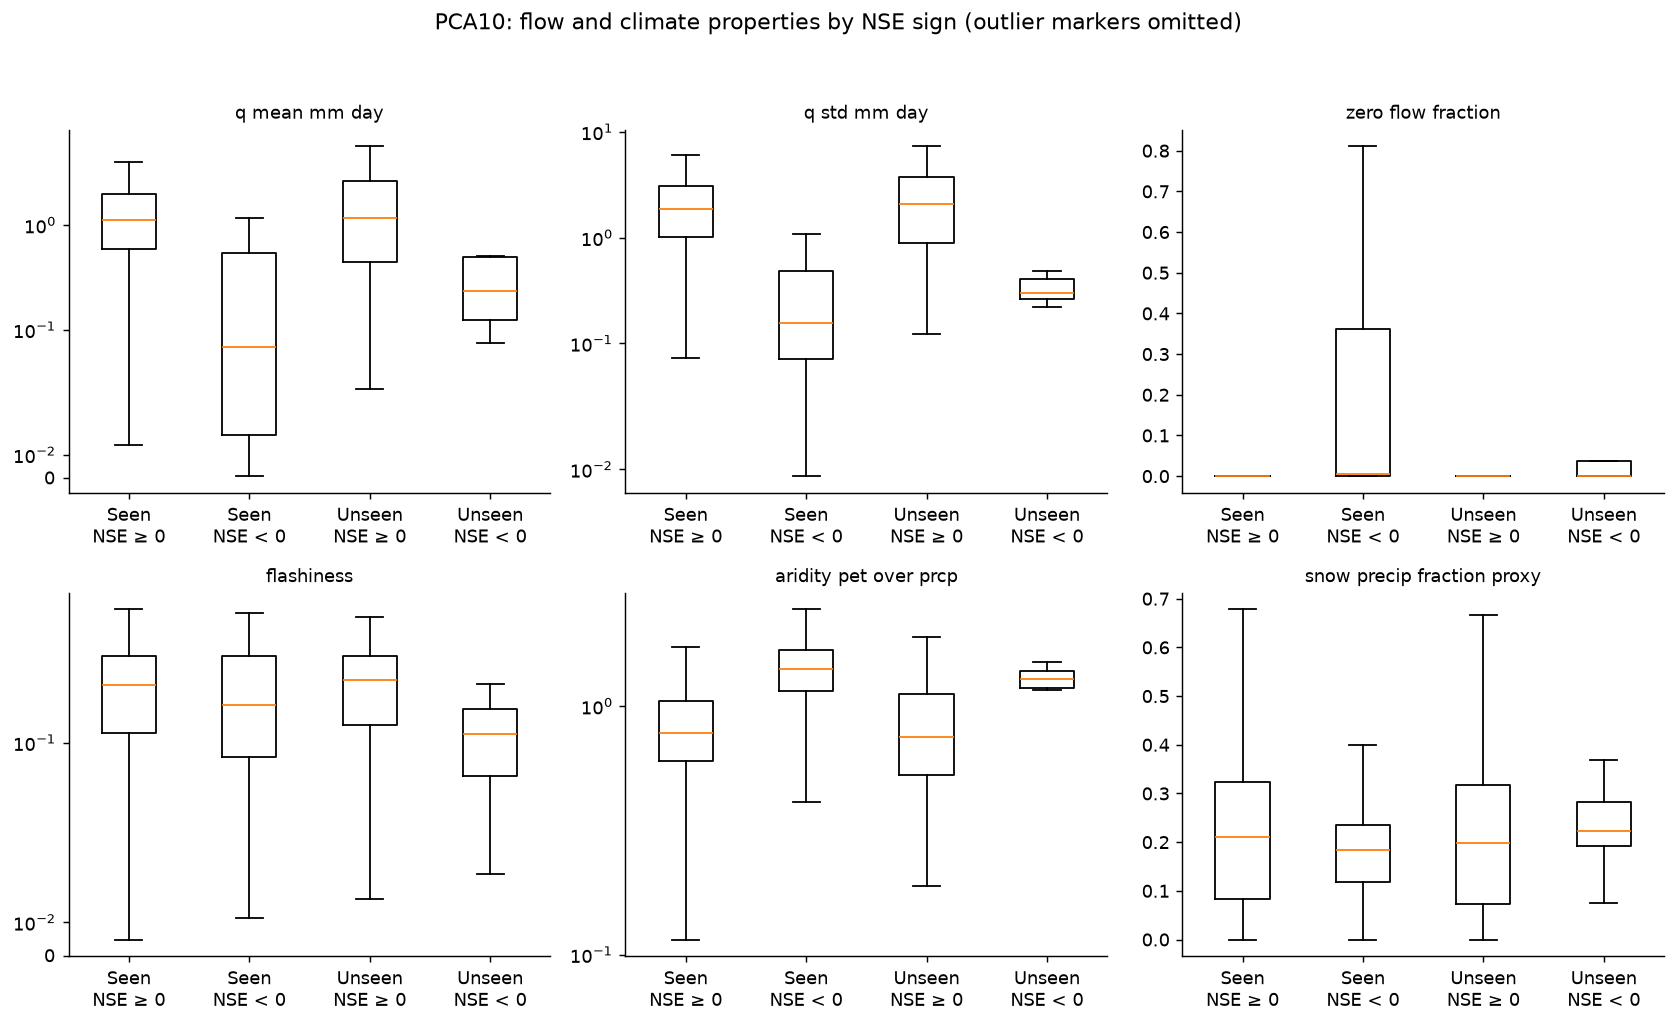

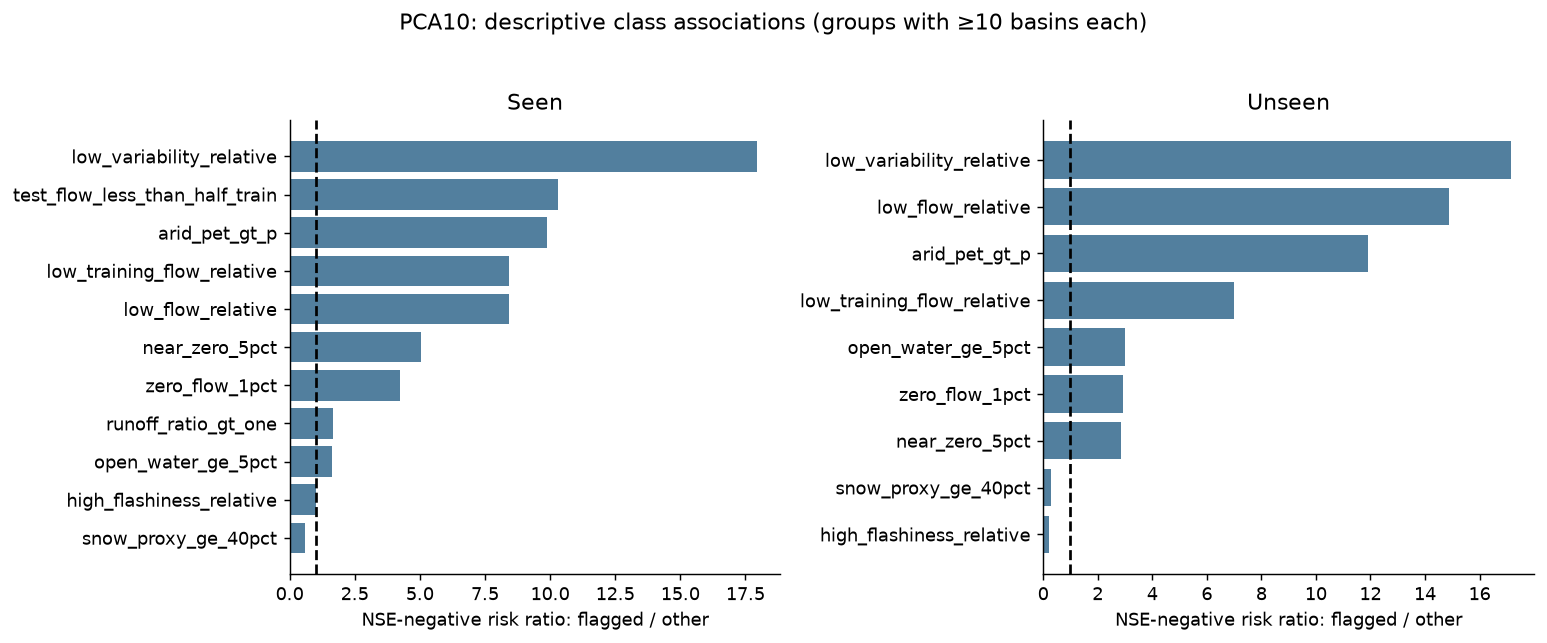

# Poor-basin performance findings

Exploratory associations only. Input: basin_diagnostic_dataset.csv.
NSE and KGE flags are analyzed separately. Extended ERA5 has a different test period.

## PCA10: Seen
NSE negative: 84/1317; KGE negative: 111/1317; KGE below mean-flow reference: 59.

- test_q_std_mm_day: negative-score median 0.1543, nonnegative-score median 1.884; rank-biserial -0.791, BH q=2.73e-32.
- test_q_max_mm_day: negative-score median 2.148, nonnegative-score median 21.6; rank-biserial -0.783, BH q=5.79e-32.
- train_q_std_mm_day: negative-score median 0.2574, nonnegative-score median 1.979; rank-biserial -0.726, BH q=1.11e-27.
- test_q_mean_mm_day: negative-score median 0.06798, nonnegative-score median 1.109; rank-biserial -0.683, BH q=1.05e-24.
- test_aridity_pet_over_prcp: negative-score median 1.408, nonnegative-score median 0.7789; rank-biserial 0.678, BH q=2.15e-24.
- train_q_mean_mm_day: negative-score median 0.08259, nonnegative-score median 1.087; rank-biserial -0.668, BH q=8.86e-24.
- test_runoff_ratio: negative-score median 0.04137, nonnegative-score median 0.3938; rank-biserial -0.627, BH q=3.76e-21.
- test_prcp_mean: negative-score median 1.36, nonnegative-score median 2.901; rank-biserial -0.613, BH q=2.91e-20.

### Example worst NSE basin IDs
- CAN_05CK005: NSE -95.068; KGE -63.866; mean Q 0.0008026 mm/day; SD 0.007058; zero-flow fraction 0.758.
- CAN_05GA012: NSE -73.834; KGE -52.513; mean Q 0.001292 mm/day; SD 0.008636; zero-flow fraction 0.736.
- CAN_05GA008: NSE -17.536; KGE -19.915; mean Q 0.003109 mm/day; SD 0.0163; zero-flow fraction 0.656.
- USA_09306242: NSE -13.895; KGE -4.083; mean Q 0.01886 mm/day; SD 0.03188; zero-flow fraction 0.000.
- USA_06477500: NSE -11.731; KGE -2.203; mean Q 0.03516 mm/day; SD 0.1684; zero-flow fraction 0.067.
- CAN_05AH050: NSE -9.829; KGE -13.558; mean Q 0.005219 mm/day; SD 0.02768; zero-flow fraction 0.755.
- USA_06409000: NSE -7.991; KGE -0.805; mean Q 0.1079 mm/day; SD 0.04645; zero-flow fraction 0.000.
- USA_06408700: NSE -7.456; KGE -0.038; mean Q 0.4544 mm/day; SD 0.07453; zero-flow fraction 0.000.

## PCA10: Unseen
NSE negative: 8/100; KGE negative: 14/100; KGE below mean-flow reference: 5.

- No continuous-feature contrasts pass the exploratory BH threshold with the minimum group size; do not interpret this as evidence of no association.

### Example worst NSE basin IDs
- USA_06876700: NSE -3.093; KGE -1.344; mean Q 0.09119 mm/day; SD 0.2365; zero-flow fraction 0.000.
- USA_06404000: NSE -1.187; KGE -2.116; mean Q 0.07424 mm/day; SD 0.2189; zero-flow fraction 0.106.
- CAN_07CA012: NSE -0.675; KGE -0.335; mean Q 0.5028 mm/day; SD 0.4843; zero-flow fraction 0.000.
- CAN_06AB001: NSE -0.657; KGE -0.369; mean Q 0.2649 mm/day; SD 0.2679; zero-flow fraction 0.000.
- CAN_07HA005: NSE -0.619; KGE 0.156; mean Q 0.1993 mm/day; SD 0.3807; zero-flow fraction 0.015.
- CAN_07MA003: NSE -0.393; KGE 0.073; mean Q 0.4895 mm/day; SD 0.268; zero-flow fraction 0.000.
- CAN_07GD001: NSE -0.270; KGE -0.136; mean Q 0.1337 mm/day; SD 0.3302; zero-flow fraction 0.104.
- CAN_01FB003: NSE -0.023; KGE 0.362; mean Q 2.73 mm/day; SD 1.555; zero-flow fraction 0.000.

## Limits and next steps
- Test-flow SD and mean are mathematically involved in efficiency scores; these are diagnostics, not causal discoveries.
- Class thresholds are study-defined proxies. Missing regulation, abstraction, rating-curve and carbonate/karst evidence limits physical attribution.
- Seen/Unseen, forcing source and testing period are analyzed separately. Geographic/nested-basin dependence and one-seed model uncertainty remain.
- Confirm patterns across seeds, years and matched climate/region subsets before using them as general research conclusions.
- Do not remove basins solely because their performance is poor; investigate the observations, forcing and model limitations.

Analysis complete. Rerun using this notebook and the one CSV only. Outputs: /home/pollen26/Desktop/LSTM_RR_Modelling/Poor_Basin_Performance_Analysis/analysis_outputs


In [8]:
plt.rcParams.update({'font.size':10,'figure.dpi':130,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(12,4.8),sharey=True)
order=['Daymet_MetOnly','Daymet_MetAttr','Daymet_PCA10','ERA5_MetAttr','ERA5_Extended']
for ax,metric in zip(axes,['NSE','KGE']):
    for split,offset,color in [('Seen',-.18,'#3569a8'),('Unseen',.18,'#dc8a36')]:
        vals=[];errs=[]
        for model in order:
            v=df[(df.experiment==model)&(df.seen_unseen==split)][metric+'_negative'].dropna();k=int(v.sum());lo,hi=wilson(k,len(v));p=v.mean()
            vals.append(p);errs.append([p-lo,hi-p])
        ax.bar(np.arange(5)+offset,vals,.34,color=color,label=split,yerr=np.asarray(errs).T,capsize=2)
    ax.set_xticks(np.arange(5),['Daymet\nMet only','Daymet\nAttributes','Daymet\nPCA10','ERA5\nAttributes','ERA5\nExtended*'])
    ax.set_title(metric+' < 0');ax.set_ylabel('Fraction of scored basins');ax.set_ylim(0,1);ax.legend()
fig.suptitle('Negative-score prevalence with 95% Wilson intervals')
fig.text(.5,.01,'*Extended ERA5 uses a different test period. Negative KGE and negative NSE have different benchmark interpretations.',ha='center',fontsize=8)
fig.tight_layout(rect=[0,.04,1,.95]);fig.savefig(OUT/'negative_score_prevalence.png',dpi=250);plt.show()

focus=df[df.experiment==PRIMARY]
features=['test_q_mean_mm_day','test_q_std_mm_day','test_zero_flow_fraction','test_flashiness','test_aridity_pet_over_prcp','test_snow_precip_fraction_proxy']
fig,axes=plt.subplots(2,3,figsize=(13,8))
for ax,feature in zip(axes.flat,features):
    data=[];labels=[]
    for split in ('Seen','Unseen'):
        for bad in (False,True):
            g=focus[(focus.seen_unseen==split)&focus.NSE.notna()&((focus.NSE<0)==bad)]
            data.append(g[feature].dropna());labels.append(split+'\n'+('NSE < 0' if bad else 'NSE ≥ 0'))
    if all(len(v) for v in data):ax.boxplot(data,tick_labels=labels,showfliers=False)
    ax.set_title(feature.replace('test_','').replace('_',' '),fontsize=10)
    if feature in ['test_q_mean_mm_day','test_q_std_mm_day','test_flashiness','test_aridity_pet_over_prcp']:ax.set_yscale('symlog',linthresh=.05)
fig.suptitle('PCA10: flow and climate properties by NSE sign (outlier markers omitted)')
fig.tight_layout(rect=[0,0,1,.95]);fig.savefig(OUT/'PCA10_flow_climate_profiles.png',dpi=250);plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,split in zip(axes,['Seen','Unseen']):
    z=risks[(risks.experiment==PRIMARY)&(risks.seen_unseen==split)&(risks.outcome=='NSE_negative')&~risks.small_group].copy()
    z=z.sort_values('risk_ratio')
    ax.barh(z.classification,z.risk_ratio,color='#527f9e');ax.axvline(1,color='black',ls='--');ax.set_title(split);ax.set_xlabel('NSE-negative risk ratio: flagged / other')
fig.suptitle('PCA10: descriptive class associations (groups with ≥10 basins each)')
fig.tight_layout(rect=[0,0,1,.95]);fig.savefig(OUT/'PCA10_class_risk_ratios.png',dpi=250);plt.show()

lines=['# Poor-basin performance findings','',
 'Exploratory associations only. Input: '+CSV_PATH.name+'.',
 'NSE and KGE flags are analyzed separately. Extended ERA5 has a different test period.','']
for split in ('Seen','Unseen'):
    h=overview[(overview.experiment==PRIMARY)&(overview.seen_unseen==split)].iloc[0]
    lines+=['## PCA10: '+split,f"NSE negative: {int(h.NSE_negative_n)}/{int(h.NSE_scored)}; KGE negative: {int(h.KGE_negative_n)}/{int(h.KGE_scored)}; KGE below mean-flow reference: {int(h.KGE_below_mean_reference_n)}.",'']
    z=contrasts[(contrasts.experiment==PRIMARY)&(contrasts.seen_unseen==split)&(contrasts.metric=='NSE')&contrasts.q_BH.lt(.05)].copy()
    z['effect_abs']=z.rank_biserial.abs()
    for r in z.sort_values('effect_abs',ascending=False).head(8).itertuples():
        lines.append(f'- {r.feature}: negative-score median {r.negative_median:.4g}, nonnegative-score median {r.nonnegative_median:.4g}; rank-biserial {r.rank_biserial:.3f}, BH q={r.q_BH:.3g}.')
    if z.empty:lines.append('- No continuous-feature contrasts pass the exploratory BH threshold with the minimum group size; do not interpret this as evidence of no association.')
    lines+=['','### Example worst NSE basin IDs']
    for r in catalog[(catalog.experiment==PRIMARY)&(catalog.seen_unseen==split)].head(8).itertuples():
        lines.append(f'- {r.basin_id}: NSE {r.NSE:.3f}; KGE {r.KGE:.3f}; mean Q {r.test_q_mean_mm_day:.4g} mm/day; SD {r.test_q_std_mm_day:.4g}; zero-flow fraction {r.test_zero_flow_fraction:.3f}.')
    lines.append('')
lines+=['## Limits and next steps',
 '- Test-flow SD and mean are mathematically involved in efficiency scores; these are diagnostics, not causal discoveries.',
 '- Class thresholds are study-defined proxies. Missing regulation, abstraction, rating-curve and carbonate/karst evidence limits physical attribution.',
 '- Seen/Unseen, forcing source and testing period are analyzed separately. Geographic/nested-basin dependence and one-seed model uncertainty remain.',
 '- Confirm patterns across seeds, years and matched climate/region subsets before using them as general research conclusions.',
 '- Do not remove basins solely because their performance is poor; investigate the observations, forcing and model limitations.']
report='\n'.join(lines)
(OUT/'FINDINGS.md').write_text(report)
display(Markdown(report))
verification=dict(status='complete',input_rows=len(df),basins=df.basin_id.nunique(),experiments=df.experiment.nunique(),
                  negative_catalog_rows=len(catalog),persistent_3of4=int(persistent.persistent_3of4.sum()),
                  missing_NSE=int(df.NSE.isna().sum()),missing_KGE=int(df.KGE.isna().sum()),
                  csv_sha256=metadata['input_sha256'],only_input=CSV_PATH.name)
(OUT/'analysis_completion.json').write_text(json.dumps(verification,indent=2))
print('Analysis complete. Rerun using this notebook and the one CSV only. Outputs:',OUT)
